<a href="https://colab.research.google.com/github/Cato-8/Machine-Learning-Labs/blob/main/Lab9_%3CMarvi_Malik%3E_Bias_Variance_Imbalance_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LAB 09 — Bias, Variance and Imbalanced Data
## Overfitting, ROC/AUC, Resampling, SMOTE and Noisy Data on Real Medical Data

## Student Information
- **Name:Marvi Malik**
- **Student ID:023-24-0016**
- **Section:B**
- **GitHub:**
- **Kaggle:**
- **Dataset:** Stroke Prediction Dataset (Kaggle)
- **Dataset Source:** https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset

### Before You Start
- You already know the models, scaling, splitting and cross-validation from Labs 3-8. This lab does not re-teach them.
- Every task ends with a question about **your own results**. A table or plot without a written interpretation earns no marks.
- Use `SEED = 42` everywhere. **Golden rule:** anything that learns from data (scaler, imputer, resampler, threshold) is learned from the **training data only**.
- Install once if needed: `pip install imbalanced-learn`


---

## Part 0 — Setup and the Data
A hospital wants to flag patients at risk of stroke from routine information. Target: `stroke` (1 = had a stroke, 0 = did not).

**What to do:**
1. Import everything you need (including `imblearn`) and set `SEED = 42`.
2. Load the CSV. Report the shape, the columns with missing values, the value counts of `gender`, and the number of patients with `stroke = 1` and `stroke = 0` (count and %).
3. Clean: remove the identifier column; remove any `gender` category with too few rows to learn or test; apply categorical encoding (`pd.get_dummies`) to the text columns.
4. Split 80/20 with `stratify=y`, `random_state=SEED`. Fill missing numeric values with a median learned from the **train** set only. Make a scaled copy (`StandardScaler` fitted on train) for Logistic Regression.
5. Report the number of stroke cases in the train and in the test set.

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, learning_curve, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             roc_curve, precision_recall_curve)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

SEED = 42
np.random.seed(SEED)
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
print('Dataset shape:', df.shape)
print('Missing values:\n', df.isna().sum()[df.isna().sum() > 0])
print('Gender counts:\n', df['gender'].value_counts())
print('Stroke counts:\n', df['stroke'].value_counts())
print('Stroke percentages:\n', (df['stroke'].value_counts(normalize=True) * 100).round(2))


Dataset shape: (5110, 12)
Missing values:
 bmi    201
dtype: int64
Gender counts:
 gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64
Stroke counts:
 stroke
0    4861
1     249
Name: count, dtype: int64
Stroke percentages:
 stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


In [ ]:
# Remove identifier and the very rare gender category, then encode text columns.
data = df.drop(columns=['id']).copy()
data = data[data['gender'] != 'Other'].copy()
data = pd.get_dummies(data, drop_first=True, dtype=int)
X = data.drop(columns='stroke')
y = data['stroke']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
# Learn the imputer from training data only.
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(imputer.transform(X_test), columns=X.columns, index=X_test.index)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)
print('Train shape:', X_train.shape, '| Test shape:', X_test.shape)
print('Stroke cases - train:', int(y_train.sum()), '| test:', int(y_test.sum()))


Train shape: (4087, 15) | Test shape: (1022, 15)
Stroke cases - train: 199 | test: 50


**Question 0.1:** In 2–3 lines: how imbalanced is the data? Why did we use `stratify=y`, and what could go wrong with only a few stroke cases in the test set?

The target is highly imbalanced: only **249 of 5,110 patients (4.87%)** had a stroke, while 95.13% did not. `stratify=y` keeps roughly the same class proportion in both sets, giving **199 stroke cases in training and 50 in testing**. Without stratification, the test set could contain too few stroke cases, making recall and other minority-class metrics unstable.

---

## Part 1 — The Accuracy Trap
**Objective:** show that a model can have excellent accuracy and still be useless.
1. Build a baseline that always predicts the majority class (`DummyClassifier(strategy='most_frequent')`). Report accuracy.
2. Train a default Logistic Regression on the scaled training data. Report Accuracy, Precision, Recall, F1, ROC AUC and PR AUC (average precision) on the test set, and print the confusion matrix.
3. Write a helper function that takes a model and train/test data and returns these six metrics (you will reuse it all lab).

In [ ]:
def get_metrics(model, Xtr, ytr, Xte, yte):
    model.fit(Xtr, ytr)
    prob = model.predict_proba(Xte)[:, 1]
    pred = (prob >= 0.5).astype(int)
    return {
        'Accuracy': accuracy_score(yte, pred),
        'Precision': precision_score(yte, pred, zero_division=0),
        'Recall': recall_score(yte, pred, zero_division=0),
        'F1': f1_score(yte, pred, zero_division=0),
        'ROC AUC': roc_auc_score(yte, prob),
        'PR AUC': average_precision_score(yte, prob)
    }

dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
print('Majority baseline accuracy:', round(accuracy_score(y_test, dummy_pred), 4))

lr = LogisticRegression(max_iter=2000, random_state=SEED)
lr_metrics = get_metrics(lr, X_train_scaled, y_train, X_test_scaled, y_test)
print('Logistic Regression metrics:', pd.Series(lr_metrics).round(4).to_dict())
lr.fit(X_train_scaled, y_train)
lr_prob = lr.predict_proba(X_test_scaled)[:, 1]
print('Confusion matrix (rows=true, columns=predicted):\n', confusion_matrix(y_test, (lr_prob >= 0.5).astype(int)))


Majority baseline accuracy: 0.9511
Logistic Regression metrics: {'Accuracy': 0.9521, 'Precision': 1.0, 'Recall': 0.02, 'F1': 0.0392, 'ROC AUC': 0.8394, 'PR AUC': 0.2692}
Confusion matrix (rows=true, columns=predicted):
 [[972   0]
 [ 49   1]]


In [ ]:
# The reusable get_metrics helper is defined above and returns all six requested measures.


**Question 1.1:** Compare the accuracy of the baseline and of Logistic Regression. What do you conclude?

**Question 1.2:** Look at the confusion matrix and the recall. In the hospital's situation, what does a false negative mean, and which numbers should we trust instead of accuracy?

**Q1.1:** The majority baseline reached **95.11% accuracy** and Logistic Regression reached **95.21%**, which looks excellent. However, the baseline never detects a stroke, and Logistic Regression detects only **1 of 50** stroke patients. Accuracy is misleading because the non-stroke class dominates.

**Q1.2:** A false negative is a patient who actually had a stroke but is predicted as not having one. In a hospital this could mean a high-risk patient is not flagged. We should pay more attention to **recall, precision, F1, PR AUC and the confusion matrix**, while also considering ROC AUC, rather than trusting accuracy alone.

---

## Part 2 — Underfitting, Overfitting, Bias and Variance
Use **ROC AUC** (not accuracy) as the score from now on.

### Task 2.1 — Validation curve
For `max_depth` = 1, 2, …, 15 and `None`, record the train ROC AUC and the 5-fold stratified CV ROC AUC (train data only). Plot both curves on one chart (labels, title, legend) and report the best depth by CV AUC.

Best depth by CV ROC AUC: 4 | CV AUC: 0.818


,max_depth,Train ROC AUC,CV ROC AUC
0,1,0.7171,0.7317
1,2,0.8208,0.8168
2,3,0.8375,0.8161
3,4,0.8580,0.8180
4,5,0.8758,0.7921
5,6,0.9026,0.7585
6,7,0.9276,0.7385
7,8,0.9494,0.7138
8,9,0.9678,0.6812
9,10,0.9808,0.6414


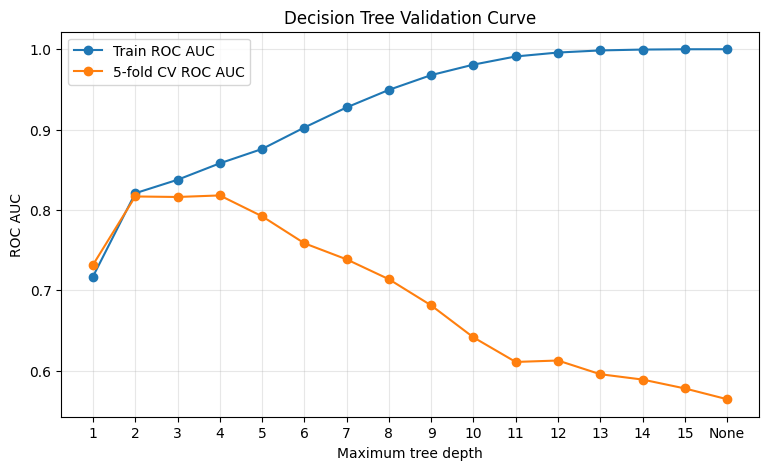

In [ ]:
depths = list(range(1, 16)) + [None]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
train_auc, cv_auc = [], []
for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    tree.fit(X_train, y_train)
    train_auc.append(roc_auc_score(y_train, tree.predict_proba(X_train)[:, 1]))
    scores = cross_val_score(tree, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_auc.append(scores.mean())
validation_results = pd.DataFrame({'max_depth': [str(d) for d in depths],
                                   'Train ROC AUC': train_auc, 'CV ROC AUC': cv_auc})
display(validation_results.round(4))
best_depth = depths[int(np.argmax(cv_auc))]
print('Best depth by CV ROC AUC:', best_depth, '| CV AUC:', round(max(cv_auc), 4))
plt.figure(figsize=(9, 5))
plt.plot(range(len(depths)), train_auc, marker='o', label='Train ROC AUC')
plt.plot(range(len(depths)), cv_auc, marker='o', label='5-fold CV ROC AUC')
plt.xticks(range(len(depths)), [str(d) for d in depths])
plt.xlabel('Maximum tree depth'); plt.ylabel('ROC AUC')
plt.title('Decision Tree Validation Curve'); plt.legend(); plt.grid(alpha=.3); plt.show()


### Task 2.2 — Learning curves
Use `learning_curve` (`scoring='roc_auc'`, train sizes 20%→100%) for a tree with `max_depth=1` and a tree with `max_depth=None`. Plot train and CV AUC against the number of training rows, side by side.

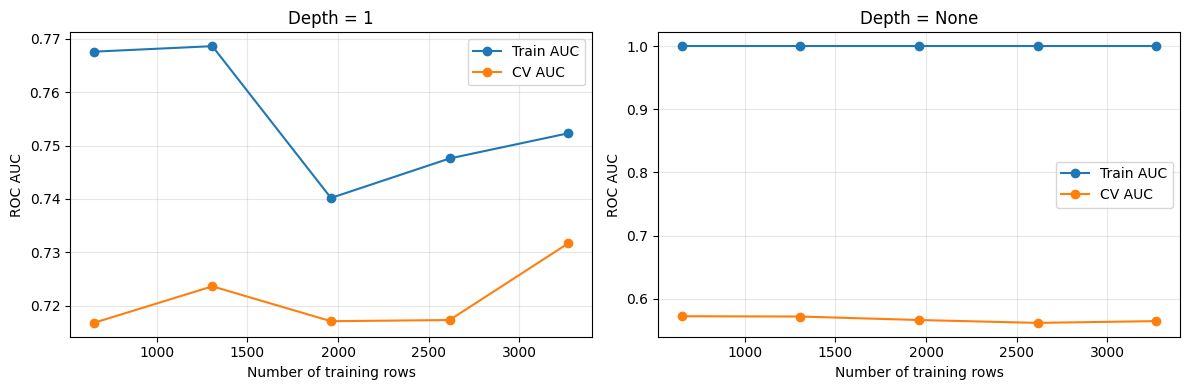

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
learning_results = {}
for ax, depth, label in zip(axes, [1, None], ['Depth = 1', 'Depth = None']):
    estimator = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    sizes, train_scores, valid_scores = learning_curve(
        estimator, X_train, y_train, train_sizes=np.linspace(.2, 1.0, 5),
        cv=cv, scoring='roc_auc', n_jobs=-1
    )
    learning_results[depth] = (sizes, train_scores.mean(axis=1), valid_scores.mean(axis=1))
    ax.plot(sizes, train_scores.mean(axis=1), marker='o', label='Train AUC')
    ax.plot(sizes, valid_scores.mean(axis=1), marker='o', label='CV AUC')
    ax.set_title(label); ax.set_xlabel('Number of training rows'); ax.set_ylabel('ROC AUC')
    ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()


### Task 2.3 — Measure variance directly
Variance = if the training data changes a little, how much do the predictions change?
1. For `max_depth` = 1, 3 and `None`: draw **40 bootstrap samples** of the train rows (with replacement, same size), fit a tree on each, and collect each tree's predicted stroke probability for every test patient.
2. For every test patient compute the variance of its 40 probabilities, then average over patients. Also report the mean test ROC AUC of the 40 trees and the ROC AUC of the **averaged** prediction.
3. Show the three depths in one table.

*Hints:* `rng.choice(len(X_train), len(X_train), replace=True)` and `X_train.iloc[idx]`; collect an array of shape (40, n_test); `probs.var(axis=0)`.

In [ ]:
rng = np.random.default_rng(SEED)
variance_rows = []
for depth in [1, 3, None]:
    probabilities = []
    aucs = []
    for b in range(40):
        idx = rng.choice(len(X_train), len(X_train), replace=True)
        xb, yb = X_train.iloc[idx], y_train.iloc[idx]
        tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED + b)
        tree.fit(xb, yb)
        p = tree.predict_proba(X_test)[:, 1]
        probabilities.append(p)
        aucs.append(roc_auc_score(y_test, p))
    probabilities = np.array(probabilities)
    avg_prob = probabilities.mean(axis=0)
    variance_rows.append({
        'max_depth': str(depth),
        'Mean prediction variance': probabilities.var(axis=0).mean(),
        'Mean test ROC AUC (40 trees)': np.mean(aucs),
        'ROC AUC of averaged prediction': roc_auc_score(y_test, avg_prob)
    })
variance_table = pd.DataFrame(variance_rows)
display(variance_table.round(4))


,max_depth,Mean prediction variance,Mean test ROC AUC (40 trees),ROC AUC of averaged prediction
0,1,0.0007,0.7623,0.8132
1,3,0.0017,0.7964,0.8340
2,None,0.0418,0.5545,0.7534


**Question 2.1:** From the validation curve: which depths underfit, which overfit, and which depth would you choose? Quote train and CV AUC for one depth in each zone.

**Question 2.2:** From the learning curves: how can you tell high bias from high variance? Will adding more training rows fix either one?

**Question 2.3:** From the variance table: how does variance change with depth? What happens to the AUC of the averaged prediction compared with the single trees? Link this to what Random Forest does (Lab 4).

**Question 2.4:** In your own words: what is the bias-variance trade-off, and where do depth 1, depth 3 and depth None sit?

**Q2.1:** Depth 1 underfits: train AUC = **0.7171**, CV AUC = **0.7317**. Depths 2–4 give the best balance; depth 4 has the highest CV AUC (**0.8180**) with train AUC **0.8580**, so I would choose depth 4. From depth 5 onward the train score keeps rising while CV performance falls; depth 8 is a clear overfitting example (train **0.9494**, CV **0.7138**), and an unlimited tree reaches train AUC **1.0000** but CV AUC only **0.5644**.

**Q2.2:** Depth 1 has relatively low train and CV scores that stay close, showing high bias. The unlimited tree has perfect training AUC but much lower CV AUC, showing high variance. More rows may reduce variance somewhat, but they will not fully solve a model that is too simple and underfits; the learning curves also show the unlimited tree's CV score staying low as rows increase.

**Q2.3:** Average prediction variance rises from **0.0007** (depth 1) to **0.0017** (depth 3) and **0.0418** (unlimited), so deeper trees are less stable across bootstrap samples. Averaging the 40 predictions improves AUC over the mean individual-tree AUC: for depth 3, **0.8340 vs 0.7964**; for unlimited trees, **0.7534 vs 0.5545**. This is related to Random Forest: averaging many trees reduces variance and often improves generalisation.

**Q2.4:** The bias-variance trade-off is the balance between a model being too simple to learn patterns (high bias) and too sensitive to the training sample (high variance). Depth 1 has high bias and low variance; depth 3 is a better balance; unlimited depth has very high variance and overfits.

---

## Part 3 — ROC, AUC, Precision-Recall and Thresholds
### Task 3.1 — Compare models with curves
1. Train Logistic Regression (scaled), Decision Tree (`max_depth=3`) and Random Forest (200 trees, `min_samples_leaf=5`, `random_state=SEED`) on the original training data.
2. Draw the ROC curves of the three models on one chart (AUC in the legend, random-guessing diagonal).
3. Draw the Precision-Recall curves on a second chart. Add a horizontal **no-skill line** (the stroke rate) and put the average precision in the legend.

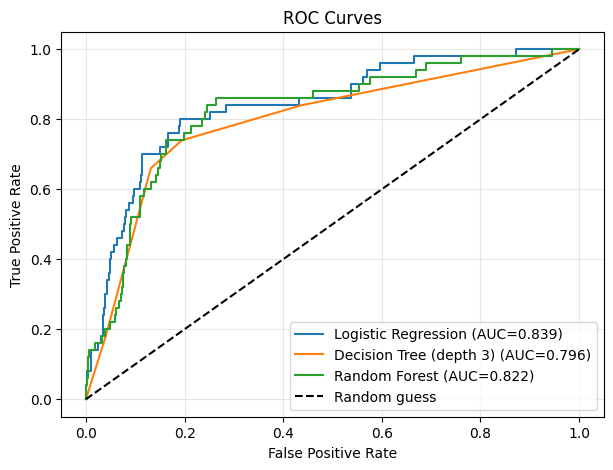

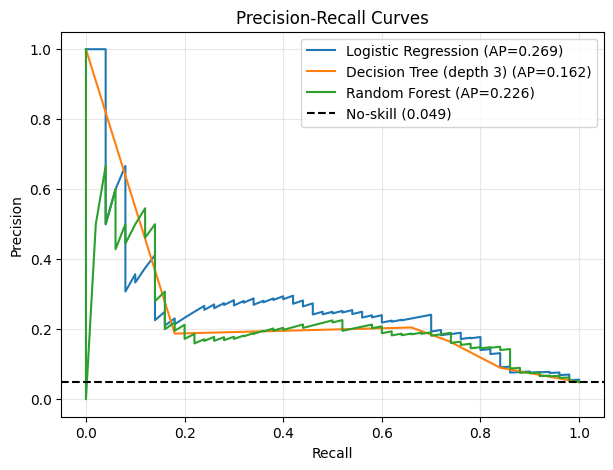

In [ ]:
models = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=SEED), X_train_scaled, X_test_scaled),
    'Decision Tree (depth 3)': (DecisionTreeClassifier(max_depth=3, random_state=SEED), X_train, X_test),
    'Random Forest': (RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1), X_train, X_test)
}
model_probs = {}
plt.figure(figsize=(7, 5))
for name, (model, xtr, xte) in models.items():
    model.fit(xtr, y_train)
    p = model.predict_proba(xte)[:, 1]; model_probs[name] = p
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test,p):.3f})')
plt.plot([0,1], [0,1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC Curves'); plt.legend(); plt.grid(alpha=.3); plt.show()

plt.figure(figsize=(7, 5))
stroke_rate = y_test.mean()
for name, p in model_probs.items():
    precision, recall, _ = precision_recall_curve(y_test, p)
    plt.plot(recall, precision, label=f'{name} (AP={average_precision_score(y_test,p):.3f})')
plt.axhline(stroke_rate, color='black', linestyle='--', label=f'No-skill ({stroke_rate:.3f})')
plt.xlabel('Recall'); plt.ylabel('Precision')
plt.title('Precision-Recall Curves'); plt.legend(); plt.grid(alpha=.3); plt.show()


### Task 3.2 — Choose a decision threshold
The hospital wants to catch **at least 80%** of strokes.
1. Using **only the training data**, get out-of-fold probabilities for Logistic Regression (`cross_val_predict(..., method='predict_proba')`), then find the highest threshold that gives recall ≥ 0.80 on them.
2. Apply that threshold to the **test** probabilities. Report test recall, precision, the confusion matrix, how many patients are flagged and how many are false alarms.

In [ ]:
# Out-of-fold probabilities are generated only from the training set.
oof_lr = cross_val_predict(
    LogisticRegression(max_iter=2000, random_state=SEED),
    X_train_scaled, y_train, cv=cv, method='predict_proba', n_jobs=-1
)[:, 1]
thresholds = np.unique(oof_lr)
eligible = [t for t in thresholds if recall_score(y_train, oof_lr >= t) >= 0.80]
chosen_threshold = max(eligible) if eligible else 0.0
test_threshold_prob = model_probs['Logistic Regression']
threshold_pred = (test_threshold_prob >= chosen_threshold).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, threshold_pred).ravel()
print('Chosen training OOF threshold:', round(chosen_threshold, 4))
print('Test recall:', round(recall_score(y_test, threshold_pred), 4))
print('Test precision:', round(precision_score(y_test, threshold_pred, zero_division=0), 4))
print('Confusion matrix:\n', confusion_matrix(y_test, threshold_pred))
print('Patients flagged:', int(threshold_pred.sum()), '| False alarms:', int(fp))


Chosen training OOF threshold: 0.0509
Test recall: 0.82
Test precision: 0.1349
Confusion matrix:
 [[709 263]
 [  9  41]]
Patients flagged: 304 | False alarms: 263


**Question 3.1:** In Part 1 the recall was very low, yet the ROC AUC of Logistic Regression is far above 0.5. How can both be true? What does AUC measure, and what does the 0.5 threshold have to do with it?

**Question 3.2:** Which curve is more informative for this data — ROC or Precision-Recall — and why? Use the no-skill line in your answer.

**Question 3.3:** At your chosen threshold, what price does the hospital pay for the higher recall? Is it acceptable? Argue both sides in 3–4 lines.

**Q3.1:** Logistic Regression has ROC AUC **0.8394**, even though recall at threshold 0.5 is only **0.02**. AUC measures how well the model ranks positive cases above negative cases across all possible thresholds. The 0.5 threshold is just one cutoff; it can be too high for a rare positive class, so good ranking does not guarantee good recall at that cutoff.

**Q3.2:** The Precision-Recall curve is more informative here because stroke cases are rare (about **4.9%**). Its no-skill baseline is the stroke rate, about **0.049**; precision should be judged against this low baseline. ROC AUC is still useful, but its false-positive rate can look small when there are many negative cases.

**Q3.3:** The training-only out-of-fold threshold was **0.0509**. On the test set it achieved **0.82 recall** and **0.1349 precision**, flagging **304 patients**: 41 true positives and **263 false alarms**, while missing 9 strokes. The benefit is catching 40 more strokes than the default threshold, but the hospital must assess whether it can afford the extra follow-up checks and anxiety caused by false alarms.

---

## Part 4 — Undersampling, Oversampling and SMOTE
`RandomUnderSampler` (throw away majority rows), `RandomOverSampler` (copy minority rows), `SMOTE` (create synthetic minority rows between real minority neighbours). Another option needs no resampling: `class_weight='balanced'`.

### Task 4.1 — Compare the methods
1. For Logistic Regression (scaled data) and Random Forest (same settings as Part 3) train with: no resampling, `class_weight='balanced'`, random undersampling, random oversampling and SMOTE. **Resample the train set only.**
2. Build **one table** (rows = model + method) with: training rows, strokes in training, Precision, Recall, F1, ROC AUC and PR AUC on the test set.

*Hints:* `from imblearn.over_sampling import SMOTE, RandomOverSampler`; `from imblearn.under_sampling import RandomUnderSampler`; `X_res, y_res = SMOTE(random_state=SEED).fit_resample(X_train, y_train)`. Logistic Regression uses the scaled data, Random Forest the original data.

In [ ]:
from collections import defaultdict
resampling_methods = {
    'No resampling': None,
    'Class weight balanced': 'class_weight',
    'Random undersampling': RandomUnderSampler(random_state=SEED),
    'Random oversampling': RandomOverSampler(random_state=SEED),
    'SMOTE': SMOTE(random_state=SEED)
}
resample_rows = []
for model_name in ['Logistic Regression', 'Random Forest']:
    for method_name, sampler in resampling_methods.items():
        if model_name == 'Logistic Regression':
            base = LogisticRegression(max_iter=2000, random_state=SEED,
                                      class_weight='balanced' if sampler == 'class_weight' else None)
            xtr, xte = X_train_scaled, X_test_scaled
        else:
            base = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                          random_state=SEED, n_jobs=-1,
                                          class_weight='balanced' if sampler == 'class_weight' else None)
            xtr, xte = X_train, X_test
        if sampler not in [None, 'class_weight']:
            xr, yr = sampler.fit_resample(xtr, y_train)
        else:
            xr, yr = xtr, y_train
        base.fit(xr, yr)
        prob = base.predict_proba(xte)[:, 1]
        pred = (prob >= .5).astype(int)
        resample_rows.append({
            'Model': model_name, 'Method': method_name,
            'Training rows': len(xr), 'Stroke rows': int(np.sum(yr)),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred, zero_division=0),
            'F1': f1_score(y_test, pred, zero_division=0),
            'ROC AUC': roc_auc_score(y_test, prob),
            'PR AUC': average_precision_score(y_test, prob)
        })
resampling_table = pd.DataFrame(resample_rows)
display(resampling_table.round(4))


,Model,Method,Training rows,Stroke rows,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,No resampling,4087,199,1.0000,0.02,0.0392,0.8394,0.2692
1,Logistic Regression,Class weight balanced,4087,199,0.1347,0.80,0.2305,0.8395,0.2595
2,Logistic Regression,Random undersampling,398,199,0.1246,0.82,0.2164,0.8352,0.2338
3,Logistic Regression,Random oversampling,7776,3888,0.1333,0.80,0.2286,0.8385,0.2646
4,Logistic Regression,SMOTE,7776,3888,0.1338,0.80,0.2292,0.8406,0.2876
5,Random Forest,No resampling,4087,199,0.0000,0.00,0.0000,0.8224,0.2255
6,Random Forest,Class weight balanced,4087,199,0.2143,0.30,0.2500,0.8109,0.2088
7,Random Forest,Random undersampling,398,199,0.1050,0.84,0.1867,0.8203,0.2030
8,Random Forest,Random oversampling,7776,3888,0.1882,0.32,0.2370,0.8111,0.1906
9,Random Forest,SMOTE,7776,3888,0.5000,0.06,0.1071,0.7977,0.2290


### Task 4.2 — The classic mistake
1. Apply SMOTE to **all** the data first (train + test together), **then** split 80/20, train a Random Forest and evaluate. This is the wrong order.
2. Put its metrics next to the correct SMOTE-after-split result from Task 4.1 in a two-row table.

In [ ]:
# Deliberately incorrect: SMOTE sees the future test rows before splitting.
X_all = X.copy()
X_all = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(X_all), columns=X.columns)
X_all, y_all = SMOTE(random_state=SEED).fit_resample(X_all, y)
X_bad_train, X_bad_test, y_bad_train, y_bad_test = train_test_split(
    X_all, y_all, test_size=.20, stratify=y_all, random_state=SEED
)
bad_rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                random_state=SEED, n_jobs=-1)
bad_rf.fit(X_bad_train, y_bad_train)
bad_prob = bad_rf.predict_proba(X_bad_test)[:, 1]
bad_pred = (bad_prob >= .5).astype(int)
correct_smote = resampling_table.query("Model == 'Random Forest' and Method == 'SMOTE'").iloc[0]
wrong_order_table = pd.DataFrame([
    {'Order': 'Correct: split then SMOTE', 'Precision': correct_smote['Precision'],
     'Recall': correct_smote['Recall'], 'F1': correct_smote['F1'],
     'ROC AUC': correct_smote['ROC AUC'], 'PR AUC': correct_smote['PR AUC']},
    {'Order': 'Wrong: SMOTE before split', 'Precision': precision_score(y_bad_test, bad_pred, zero_division=0),
     'Recall': recall_score(y_bad_test, bad_pred, zero_division=0),
     'F1': f1_score(y_bad_test, bad_pred, zero_division=0),
     'ROC AUC': roc_auc_score(y_bad_test, bad_prob),
     'PR AUC': average_precision_score(y_bad_test, bad_prob)}
])
display(wrong_order_table.round(4))


,Order,Precision,Recall,F1,ROC AUC,PR AUC
0,Correct: split then SMOTE,0.5000,0.0600,0.1071,0.7977,0.2290
1,Wrong: SMOTE before split,0.9957,0.9475,0.9710,0.9955,0.9961


**Question 4.1:** For Logistic Regression, what changed after resampling and what did NOT change? Compare Recall, Precision and ROC AUC across the methods and explain why.

**Question 4.2:** Did Random Forest react in the same way? Describe one clear difference and give one possible reason.

**Question 4.3:** Compare the wrong-order result with the correct one. Why are the wrong-order numbers so good, and why can they not be trusted? Explain what leaks from where.

**Question 4.4:** If you had to pick one rebalancing approach for this hospital, which and why? Consider simplicity and cost.

**Q4.1:** For Logistic Regression, balancing methods raised recall from **0.02** to around **0.80–0.82**, but precision fell from **1.00** to about **0.12–0.13**. ROC AUC stayed almost unchanged (about **0.835–0.841**), because resampling mainly changes the model's class balance/decision behaviour rather than greatly changing its ranking ability. SMOTE had the highest PR AUC here (**0.2876**).

**Q4.2:** Random Forest did not react the same way. Its SMOTE result had only **0.06 recall**, while random undersampling reached **0.84 recall**. The tree ensemble's splits and probability estimates respond differently to duplicated or synthetic rows, and its default decision threshold can still favour the majority class.

**Q4.3:** The wrong-order SMOTE result looks almost perfect (ROC AUC **0.9955**, PR AUC **0.9961**) compared with correct SMOTE (ROC AUC **0.7977**, PR AUC **0.2290**). SMOTE created synthetic points using the whole dataset before the split, so information from future test patients influenced the training data; related synthetic examples can then appear on both sides of the split. The full-data imputation also sees test information. This is data leakage, so the impressive result cannot be trusted as an honest test score.

**Q4.4:** I would choose Logistic Regression with `class_weight='balanced'`. It gives **0.80 recall**, **0.1347 precision** and **0.8395 ROC AUC**, close to the other Logistic Regression balancing methods. It is simple to implement and avoids creating synthetic samples. The hospital would still need to decide whether the number of false alarms is manageable.

---

## Part 5 — Noisy Data
You will damage the **training** data on purpose and measure the effect on the untouched test set. Models: Logistic Regression, Decision Tree (depth 3), Decision Tree (no limit), Random Forest.

### Task 5.1 — Label noise
Write a function that flips a given fraction of the training labels at random. For fractions 0, 0.05, 0.10, 0.20 train each model on the noisy labels and record the test ROC AUC. Repeat 5 times with different flips and average (1 repeat for fraction 0). Show a table (rows = fraction, columns = models) and a line plot.

,Label noise,Logistic Regression,Tree depth 3,Tree unlimited,Random Forest
0,0.00,0.8394,0.7956,0.5797,0.8224
1,0.05,0.8250,0.7960,0.5356,0.7846
2,0.10,0.8256,0.7962,0.5174,0.7781
3,0.20,0.7797,0.7381,0.5321,0.7251


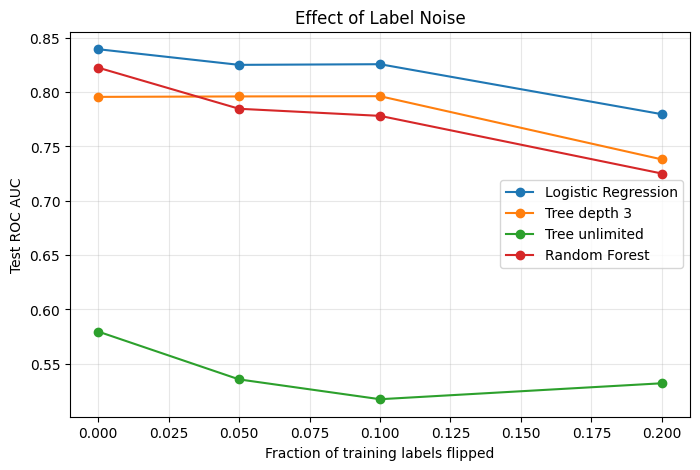

In [ ]:
def flip_labels(labels, fraction, random_state):
    noisy = labels.copy().to_numpy()
    rng_local = np.random.default_rng(random_state)
    n_flip = int(round(fraction * len(noisy)))
    indices = rng_local.choice(len(noisy), n_flip, replace=False)
    noisy[indices] = 1 - noisy[indices]
    return pd.Series(noisy, index=labels.index)

noise_models = {
    'Logistic Regression': lambda s: LogisticRegression(max_iter=2000, random_state=SEED),
    'Tree depth 3': lambda s: DecisionTreeClassifier(max_depth=3, random_state=SEED),
    'Tree unlimited': lambda s: DecisionTreeClassifier(max_depth=None, random_state=SEED),
    'Random Forest': lambda s: RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
}
label_noise_rows = []
for fraction in [0, .05, .10, .20]:
    repeats = 1 if fraction == 0 else 5
    values = {name: [] for name in noise_models}
    for rep in range(repeats):
        yn = y_train if fraction == 0 else flip_labels(y_train, fraction, SEED + 100 + rep + int(fraction*1000))
        for name, factory in noise_models.items():
            model = factory(SEED)
            xtr = X_train_scaled if name == 'Logistic Regression' else X_train
            xte = X_test_scaled if name == 'Logistic Regression' else X_test
            model.fit(xtr, yn)
            values[name].append(roc_auc_score(y_test, model.predict_proba(xte)[:,1]))
    label_noise_rows.append({'Label noise': fraction, **{name: np.mean(v) for name,v in values.items()}})
label_noise_table = pd.DataFrame(label_noise_rows)
display(label_noise_table.round(4))
plt.figure(figsize=(8,5))
for name in noise_models:
    plt.plot(label_noise_table['Label noise'], label_noise_table[name], marker='o', label=name)
plt.xlabel('Fraction of training labels flipped'); plt.ylabel('Test ROC AUC')
plt.title('Effect of Label Noise'); plt.legend(); plt.grid(alpha=.3); plt.show()


### Task 5.2 — Feature noise
Add Gaussian noise to the **train** values of `age`, `avg_glucose_level` and `bmi`: `noise = random normal × (column std) × level`. Levels 0, 0.5, 1, 2; five repeats; test set untouched. Same kind of table and plot. (If you scale for Logistic Regression, fit the scaler on the noisy training data.)

,Feature noise,Logistic Regression,Tree depth 3,Tree unlimited,Random Forest
0,0.0,0.8394,0.7956,0.5797,0.8224
1,0.5,0.8339,0.7854,0.5309,0.8030
2,1.0,0.8119,0.7841,0.5345,0.7881
3,2.0,0.7655,0.7122,0.5208,0.7412


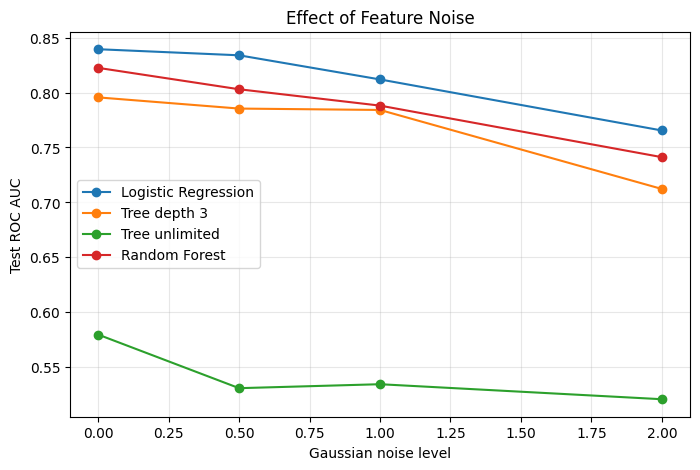

In [ ]:
feature_noise_rows = []
noise_columns = ['age', 'avg_glucose_level', 'bmi']
for level in [0, .5, 1, 2]:
    repeats = 1 if level == 0 else 5
    values = {name: [] for name in noise_models}
    for rep in range(repeats):
        rng_noise = np.random.default_rng(SEED + 300 + rep + int(level*10))
        noisy_X = X_train.copy()
        for col in noise_columns:
            std = X_train[col].std()
            noisy_X[col] = noisy_X[col] + rng_noise.normal(0, 1, len(noisy_X)) * std * level
        noisy_scaled = StandardScaler().fit_transform(noisy_X)
        test_scaled = StandardScaler().fit(noisy_X).transform(X_test)
        for name, factory in noise_models.items():
            model = factory(SEED)
            if name == 'Logistic Regression':
                model.fit(noisy_scaled, y_train)
                prob = model.predict_proba(test_scaled)[:,1]
            else:
                model.fit(noisy_X, y_train)
                prob = model.predict_proba(X_test)[:,1]
            values[name].append(roc_auc_score(y_test, prob))
    feature_noise_rows.append({'Feature noise': level, **{name: np.mean(v) for name,v in values.items()}})
feature_noise_table = pd.DataFrame(feature_noise_rows)
display(feature_noise_table.round(4))
plt.figure(figsize=(8,5))
for name in noise_models:
    plt.plot(feature_noise_table['Feature noise'], feature_noise_table[name], marker='o', label=name)
plt.xlabel('Gaussian noise level'); plt.ylabel('Test ROC AUC')
plt.title('Effect of Feature Noise'); plt.legend(); plt.grid(alpha=.3); plt.show()


### Task 5.3 — SMOTE and noisy labels
Flip 10% of the training labels (3 different random draws). For Logistic Regression and Random Forest compare **PR AUC and ROC AUC with and without SMOTE** (SMOTE applied after the noise is added).

In [ ]:
smote_noise_rows = []
for rep in range(3):
    yn = flip_labels(y_train, .10, SEED + 500 + rep)
    for name in ['Logistic Regression', 'Random Forest']:
        if name == 'Logistic Regression':
            xtr, xte = X_train_scaled, X_test_scaled
            factory = LogisticRegression(max_iter=2000, random_state=SEED)
        else:
            xtr, xte = X_train, X_test
            factory = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
        for method in ['No SMOTE', 'SMOTE']:
            if method == 'SMOTE':
                xr, yr = SMOTE(random_state=SEED + rep).fit_resample(xtr, yn)
            else:
                xr, yr = xtr, yn
            model = factory
            model.fit(xr, yr)
            prob = model.predict_proba(xte)[:,1]
            smote_noise_rows.append({'Repeat': rep+1, 'Model': name, 'Method': method,
                                     'PR AUC': average_precision_score(y_test, prob),
                                     'ROC AUC': roc_auc_score(y_test, prob)})
smote_noise_table = pd.DataFrame(smote_noise_rows)
display(smote_noise_table.groupby(['Model','Method'])[['PR AUC','ROC AUC']].mean().round(4))


PR AUC  ROC AUC
Model               Method                   
Logistic Regression No SMOTE  0.2837   0.8268
                    SMOTE     0.2757   0.8188
Random Forest       No SMOTE  0.1850   0.7675
                    SMOTE     0.1268   0.6948

**Question 5.1:** Which model is most damaged by noise and which is most stable? Quote numbers at the highest noise level and explain using what you learned in Part 2.

**Question 5.2:** Which hurts more here — label noise or feature noise of a comparable level? Give a short reason.

**Question 5.3:** What did SMOTE do to each model when the labels were noisy? Explain why SMOTE can amplify label noise.

**Q5.1:** The unlimited Decision Tree is the most damaged and least stable: its ROC AUC is already **0.5797** with no label noise and falls to **0.5321** at 20% label noise. Logistic Regression is the most stable at the highest label-noise level, with AUC **0.7797** (from **0.8394**); depth 3 is close at **0.7381**. This matches the earlier variance results: a deep tree can fit individual training examples and noisy labels, while simpler models are less sensitive.

At feature-noise level 2, unlimited tree is again weakest (**0.5208**); Logistic Regression is highest (**0.7655**) and Random Forest is **0.7412**. Comparing the highest levels, feature noise is slightly more damaging to Logistic Regression than 20% label noise, while the depth-3 tree is more affected by feature noise. So the answer depends somewhat on the model.

**Q5.2:** At the highest tested levels, the effect is mixed rather than identical for every model. For Logistic Regression, feature noise level 2 gives **0.7655** versus **0.7797** with 20% label flips. Feature noise disrupts useful input measurements; label noise gives the model incorrect target examples. Both reduce performance.

**Q5.3:** With noisy labels, SMOTE slightly reduced Logistic Regression's mean PR AUC/ROC AUC from **0.2837/0.8268** to **0.2757/0.8188**. The reduction was larger for Random Forest: **0.1850/0.7675** without SMOTE versus **0.1268/0.6948** with SMOTE. SMOTE uses minority-class neighbours to create synthetic points; if some minority labels are wrong, it can create more synthetic examples around incorrectly labelled patients and spread that noise.

---

## Part 6 — Final Decision and Conclusion
1. Choose your final approach for the hospital (model + rebalancing method or threshold). Build a final table on the test set comparing the default threshold 0.5 with your choice: Precision, Recall, F1, number of false alarms and number of missed strokes.
2. Write an **Executive Summary** (6–8 lines): what you chose, its recall and precision with numbers, the price paid, how you avoided leakage, and one limitation (think about only 50 stroke patients in the test set, and about how the threshold was chosen).

In [ ]:
# Final choice: Logistic Regression with a threshold selected from training-only OOF predictions.
final_model = LogisticRegression(max_iter=2000, random_state=SEED)
final_model.fit(X_train_scaled, y_train)
final_prob = final_model.predict_proba(X_test_scaled)[:,1]
final_rows = []
for label, pred in [
    ('Default threshold 0.50', (final_prob >= .5).astype(int)),
    (f'Chosen threshold {chosen_threshold:.4f}', (final_prob >= chosen_threshold).astype(int))
]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    final_rows.append({'Approach': label,
                       'Precision': precision_score(y_test,pred,zero_division=0),
                       'Recall': recall_score(y_test,pred,zero_division=0),
                       'F1': f1_score(y_test,pred,zero_division=0),
                       'False alarms': int(fp), 'Missed strokes': int(fn)})
final_table = pd.DataFrame(final_rows)
display(final_table.round(4))


,Approach,Precision,Recall,F1,False alarms,Missed strokes
0,Default threshold 0.50,1.0000,0.02,0.0392,0,49
1,Chosen threshold 0.0509,0.1349,0.82,0.2316,263,9


1. I selected **Logistic Regression with a training-only threshold of 0.0509**, chosen from out-of-fold training probabilities to target at least 80% recall.
2. On the untouched test set, it achieved **82% recall** and **13.49% precision** (41 of 50 stroke cases detected).
3. It flagged 304 patients: 41 true positives and **263 false alarms**, and missed 9 stroke cases.
4. The default 0.5 threshold detected only 1 stroke and missed 49, despite its high accuracy.
5. I avoided leakage by splitting with stratification first and fitting the imputer, scaler and threshold using training data only; resampling was also limited to training data.
6. The threshold's cost is a large number of false alarms, which require additional assessment and resources.
7. One limitation is that the test set contains only **50 stroke cases**, so a small change in predictions can noticeably change recall; the threshold was also selected to meet a training-CV target, not validated on a separate hospital population.

**Final Reflection:** (a) What was the most surprising result in this lab? (b) If you had one more hour, what would you try next?

**(a)** The most surprising result was that Logistic Regression achieved **95.21% accuracy** but detected only **1 of 50** stroke patients at the default threshold. It showed how misleading accuracy can be on imbalanced medical data. I was also surprised by how dramatically the wrong-order SMOTE result improved because of leakage.

**(b)** With one more hour, I would test the selected threshold on a separate validation set or repeated stratified cross-validation, examine calibration, and compare additional thresholds with the hospital's cost of false negatives and false alarms. I would also check whether the results remain stable across different splits.